# 2 — Les moyennes journalières masquent-elles la dynamique ?

**Question :** Les valeurs horaires et les changements en fin de journée améliorent-ils la prévision, à algorithme et dates inchangés ?

## Protocole commun

Prévision émise à **00 h UTC du jour cible** : toutes les entrées proviennent de la veille
ou de jours antérieurs, avec une dernière observation à 23 h UTC. La cible est le maximum
des 24 températures horaires du jour cible UTC. ERA5 est une réanalyse disponible avec retard :
cette étude rétrospective ne simule pas la disponibilité d'un service de prévision en direct.

Le fichier `experiments/protocol.json` fixe les hypothèses et les paramètres. On évalue trois
fenêtres successives couvrant 2025, avec entraînement croissant. Dans chaque fenêtre,
les 90 derniers jours de développement servent à l'arrêt anticipé ; une journée est purgée
aux frontières. On réentraîne ensuite sur le développement avec le nombre d'arbres retenu.
Le choix entre variantes se fait sur la MAE pondérée par les effectifs des fenêtres 2025,
**avant** l'évaluation sur janvier–septembre 2026. La persistance reste une référence séparée.

L'année 2026 ayant déjà été consultée auparavant, ses résultats sont exploratoires.
Les modifications du protocole doivent produire une nouvelle expérience et un nouveau commit.
Aucun hyperparamètre n'est ajusté pour obtenir un meilleur score sur 2026.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "flake.nix").exists())
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
from research_features import load_research_data, protocol
from research_evaluation import evaluate_suite, summarize_cv
from research_reporting import report, plot_cells
pd.set_option("display.max_columns", 20)


/nix/store/nigd81xp2fkmdlyh0a45lk1k21q2h1mk-python3-3.10.6-env/lib/python3.10/site-packages/xgboost/compat.py:36: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  from pandas import MultiIndex, Int64Index


## Variables et hypothèse

On conserve les agrégats quotidiens et les historiques J−1/J−2 de Nantes. On ajoute
température, pression, humidité et composantes u/v du vent à 06 h, 12 h, 18 h et 23 h UTC de J.
On mesure aussi leurs changements de fin de journée sur 6 et 12 h (23−17 h et 23−11 h,
pour température, pression et u/v). Ces 28 nouvelles colonnes ne requièrent aucune donnée de J+1.

Le calendrier est absent de cette ablation pour isoler l'apport des observations horaires.
La comparaison XGBoost/Ridge sert à distinguer un effet d'information d'un effet du modèle.
Le calendrier et l'heure sont en UTC ; ne pas comparer directement ces Tmax aux anciens jours
en heure locale. Les nouvelles variantes partagent toutes la même définition de la cible.

In [2]:
frame, groups, cells, data_path = load_research_data(spatial=False)
print(f"{len(frame)} paires : {frame['target_date'].min().date()} → {frame['target_date'].max().date()}")
display(pd.DataFrame([{"groupe": k, "nombre_variables": len(v)} for k, v in groups.items()]))
display(frame[["date", "target_date", "issue_time", "last_observation_time", "temperature_max", "tmax_next_day"]].head())
assert (frame["last_observation_time"] < frame["issue_time"]).all()


994 paires : 2024-01-04 → 2026-09-23


,groupe,nombre_variables
0,daily,18
1,hourly,28


,date,target_date,issue_time,last_observation_time,temperature_max,tmax_next_day
0,2024-01-03,2024-01-04,2024-01-04 00:00:00+00:00,2024-01-03 23:00:00+00:00,12.7,13.2
1,2024-01-04,2024-01-05,2024-01-05 00:00:00+00:00,2024-01-04 23:00:00+00:00,13.2,10.8
2,2024-01-05,2024-01-06,2024-01-06 00:00:00+00:00,2024-01-05 23:00:00+00:00,10.8,9.3
3,2024-01-06,2024-01-07,2024-01-07 00:00:00+00:00,2024-01-06 23:00:00+00:00,9.3,6.6
4,2024-01-07,2024-01-08,2024-01-08 00:00:00+00:00,2024-01-07 23:00:00+00:00,6.6,3.8


In [3]:
daily = groups["daily"]
with_hourly = daily + groups["hourly"]
variants = {
    "xgb_daily": {"columns": daily},
    "xgb_daily_hourly": {"columns": with_hourly},
    "ridge_daily": {"columns": daily, "algorithm": "ridge"},
    "ridge_daily_hourly": {"columns": with_hourly, "algorithm": "ridge"},
}


## Expérience et enregistrement

Le code commun est dans `scripts/research_features.py` et `scripts/research_evaluation.py`.
Chaque variante utilise les mêmes lignes ; les colonnes et les paramètres sont explicitement
enregistrés avec les nombres d'arbres, les empreintes du dataset et du code.
Les températures restent en °C. XGBoost ne reçoit pas de standardisation globale ; Ridge
ajuste son standardiseur uniquement sur la période d'entraînement de chaque fenêtre.

In [4]:
scores, predictions, lag_scores, intervals, selected, output = evaluate_suite(
    frame, variants, "02_hourly_information", data_path
)


02_hourly_information — cv_2025_spring : 120 jours


02_hourly_information — cv_2025_summer : 123 jours


02_hourly_information — cv_2025_autumn : 122 jours


Choix figé sur les fenêtres 2025 : ridge_daily_hourly


02_hourly_information — test_2026 : 266 jours


## Résultats : niveau, variations et pics

La MAE globale est la métrique principale. Les fortes variations sont définies **avant** les résultats
par |Tmax(J+1) − Tmax(J)| ≥ 4 °C, avec refroidissements et réchauffements séparés.
Les journées chaudes utilisent le 90e percentile des cibles du développement de chaque fenêtre,
jamais un seuil calculé sur le test. Il ne s'agit pas d'une définition de canicule.

Le gain positif signifie une erreur inférieure à la persistance. Les intervalles descriptifs
par bootstrap de blocs de sept jours tiennent partiellement compte de l'autocorrélation,
sans garantir la généralisation à d'autres années ni corriger les comparaisons multiples.

Moyenne pondérée des trois fenêtres 2025 (choix du modèle) :


,MAE_C,MAE_large_changes_C,n,n_large_changes,gain_vs_persistence_C
variant,,,,,
persistence,2.176,5.575,365,55,0.000
xgb_daily,2.153,3.979,365,55,0.023
xgb_daily_hourly,2.059,3.682,365,55,0.117
ridge_daily,2.135,4.543,365,55,0.042
ridge_daily_hourly,1.996,3.853,365,55,0.180


Choix sur 2025, maintenu pour 2026 : ridge_daily_hourly
Test descriptif 2026 — MAE en °C et effectifs :


,MAE_C,RMSE_C,bias_C,n,n_large_changes,MAE_large_changes_C,MAE_cooling_C,MAE_warming_C,MAE_warm_days_C,gain_vs_persistence_C
variant,,,,,,,,,,
persistence,2.039,2.778,-0.091,266,41,5.683,5.695,5.670,2.379,0.000
xgb_daily,2.665,3.795,-1.708,266,41,4.561,3.515,5.659,4.468,-0.626
xgb_daily_hourly,2.353,3.301,-1.355,266,41,3.742,2.588,4.953,3.756,-0.314
ridge_daily,2.078,2.644,-0.570,266,41,4.514,3.921,5.136,2.644,-0.039
ridge_daily_hourly,1.988,2.564,-0.527,266,41,3.799,2.918,4.725,2.503,0.051


Gain vs persistance : intervalle descriptif par blocs de 7 jours (sans correction pour comparaisons multiples) :


,gain_low_C,gain_high_C
variant,,
persistence,0.000,0.000
ridge_daily,-0.188,0.099
ridge_daily_hourly,-0.134,0.239
xgb_daily,-1.234,-0.132
xgb_daily_hourly,-0.810,0.114


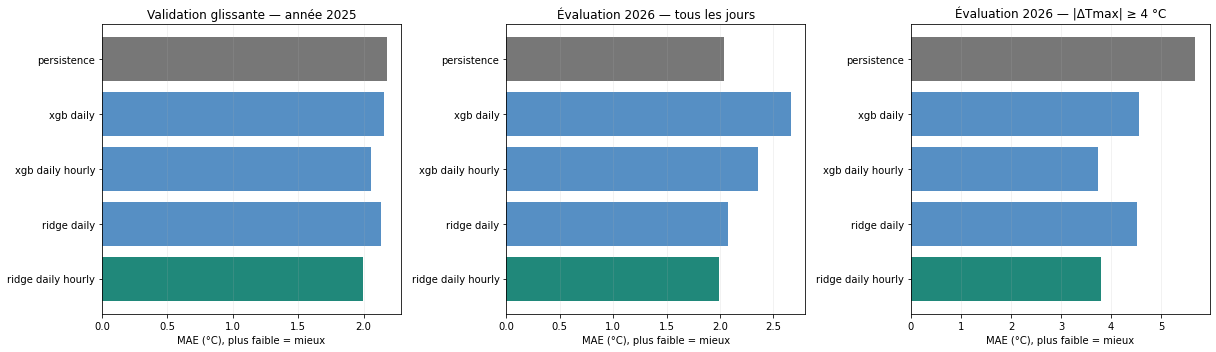

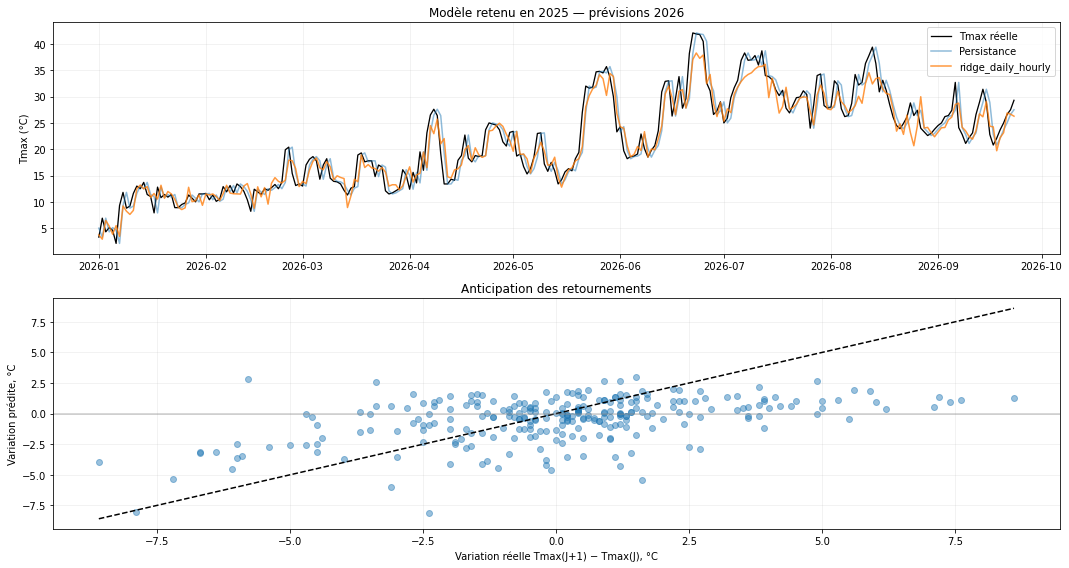

Diagnostic de décalage : vérité comparée à date_cible + décalage. -1 = la veille.


,MAE_truth_date_plus_-1_C,MAE_truth_date_plus_0_C,MAE_truth_date_plus_1_C
variant,,,
persistence,0.000,2.040,3.060
xgb_daily,1.922,2.665,3.252
xgb_daily_hourly,1.847,2.354,3.010
ridge_daily,1.031,2.071,2.860
ridge_daily_hourly,1.333,1.984,2.829


Un minimum à -1 signale une ressemblance avec la veille ; il ne prouve pas une erreur de dates.
MAE par mois cible, mêmes jours pour tous les modèles :


variant,persistence,ridge_daily,ridge_daily_hourly,xgb_daily,xgb_daily_hourly
month,,,,,
2026-01,1.687,1.690,1.526,1.337,1.376
2026-02,1.454,1.512,1.540,1.395,1.303
2026-03,1.526,1.567,1.496,1.551,1.563
2026-04,2.423,2.406,2.333,2.406,2.027
2026-05,2.158,2.084,2.024,2.989,2.539
2026-06,2.770,2.770,2.392,4.282,3.517
2026-07,2.129,2.400,2.065,4.618,3.921
2026-08,2.045,2.149,2.499,3.272,2.957
2026-09,2.170,2.108,1.997,1.845,1.743


Les effectifs des fortes variations sont limités ; pas de conclusion causale sur les fronts météorologiques.


In [5]:
report(scores, predictions, lag_scores, intervals, selected, output)


## Interprétation et limites

Un gain global sans gain sur les refroidissements ne valide pas l'hypothèse d'anticipation des fronts.
À l'inverse, un gain sur quelques pics peut être instable : regarder les effectifs, les trois fenêtres
2025 et les mois de 2026. Ne pas confondre mauvaise information, décalage d'alignement et faible
extrapolation du modèle. Cette étude ne mesure pas directement les fronts ni les masses d'air.
L'absence de gain avec ces variables ne prouve pas que toute information spatiale est inutile.

Avec moins de trois années et environ mille journées, les réseaux neuronaux ne sont pas la prochaine
étape automatique. Une confirmation sur des années supplémentaires et des prévisions archivées
disponibles à l'heure d'émission sera nécessaire avant une conclusion opérationnelle.

Sources : [Open-Meteo, réanalyse et paramètres](https://open-meteo.com/en/docs/historical-weather-api),
[évaluation temporelle](https://scikit-learn.org/stable/modules/cross_validation.html),
[complexité et régularisation XGBoost](https://xgboost.readthedocs.io/en/stable/tutorials/param_tuning.html).

In [6]:
cv = summarize_cv(scores)
test = scores.loc[scores["window"].eq("test_2026")].set_index("variant")
print(f"Variante choisie en 2025 : {selected}")
print(f"MAE 2025 : {cv.loc[selected, 'MAE_C']:.3f} °C ; persistance : {cv.loc['persistence', 'MAE_C']:.3f} °C")
print(f"MAE 2026 : {test.loc[selected, 'MAE_C']:.3f} °C ; persistance : {test.loc['persistence', 'MAE_C']:.3f} °C")
print(f"MAE 2026 sur fortes variations : {test.loc[selected, 'MAE_large_changes_C']:.3f} °C ; n = {test.loc[selected, 'n_large_changes']}")
print(f"Traces et figures enregistrées dans {output.relative_to(PROJECT_ROOT)}")


Variante choisie en 2025 : ridge_daily_hourly
MAE 2025 : 1.996 °C ; persistance : 2.176 °C
MAE 2026 : 1.988 °C ; persistance : 2.039 °C
MAE 2026 sur fortes variations : 3.799 °C ; n = 41
Traces et figures enregistrées dans experiments/results/02_hourly_information
